# Magnification, distortion and telecentricity as Zernikes

Most of the aberration notebooks (15, 17, 21, 33, 45) ask how a wavefront
error *blurs* a focus. This one asks *where* the focus lands. In a projection
lens, and above all in lithography where layers must overlay to a few
nanometres, the placement of the image over the field matters as much as its
sharpness. Three properties describe it:

- **magnification**: the image scale, a displacement linear in the field,
- **distortion**: the displacement that is not linear in the field (third
  and fifth order radial, and, in a real lens with errors, anamorphic,
  skew, keystone and bow terms of the overlay "grid"),
- **telecentricity**: the direction from which the light arrives at the
  image point, which turns a focus error into a displacement.

In the language of the wavefront they map onto the Zernike expansion as
follows:

- Placement is the **tilt** $Z_2$, $Z_3$ of the wavefront, *referred to the
  nominal image point* $m\,h$ (magnification $m$ times object point $h$).
  A coefficient $c_2$ (waves) moves the image by $-c_2\,\lambda/\mathrm{NA}$.
  Magnification and distortion are the **field dependence** of these two
  coefficients: Hopkins' wave aberration expansion
  $W(\mathbf H, \boldsymbol\rho)$ has the terms
  $W_{111}\,H\rho\cos\phi$ (a change of magnification) and
  $W_{311}\,H^3\rho\cos\phi$ (third order distortion). Design programs report
  the chief ray instead, which is not the same thing when the lens has coma.
- Telecentricity lives **not in the phase** but in the **amplitude**: in
  the centroid $\langle P\rangle$ of the light in the pupil. A pupil
  decentred against the axis, or an apodization with an intensity tilt
  ($Z_2$, $Z_3$ of the *intensity*), makes the image move through focus. In
  Zernike terms the defocus $Z_4$ becomes an effective tilt
  $4\,c_4\langle P\rangle$.

The notebook works this out with real ray traced lenses from
`pyoptics.raytrace`: Caldwell's KrF lithography lens (`caldwell_krf_lens()`,
NA 0.56, 4x, telecentric on both sides, notebooks 41 and 44) and the Zeiss
ArF immersion design (`zeiss_arfi_lens()`, NA 1.35, 8x, notebook 33), whose
image side chief rays are tilted by up to 40 mrad. The tools are
`litho.lens_aberrations()` (Zernikes on the pupil $P = n'\mathbf d_{xy}/\mathrm{NA}$,
chief ray distortion and telecentricity), `litho.lens_telecentricity()` (the
centroid of the light), `System.pupil_closeness()` (which surfaces act on
the field and which on the pupil), `System.third_order()` (the Seidel
distortion), and `ZernikeSurface` for freeform plates.

**Contents.** 1. One field point and three answers to "where is the
image": chief ray, Zernike tilt and PSF centroid. 2. Caldwell's lens over the
field: magnification and distortion as $Z_2$/$Z_3$ field maps, against the
Seidel sum. 3. The vocabulary of overlay grid terms and their Zernike field
polynomials. 4. Where grid terms come from: freeform plates near the field
and near the pupil, and element shifts (the lens manipulators of a
scanner). 5. Telecentricity: the theorem on a toy pupil, the two real lenses
over the field, a wave optical check, and how telecentricity turns
defocus and wafer tilt into grid terms.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap

from pyoptics.raytrace import (caldwell_krf_lens, zeiss_arfi_lens, fused_silica, Surface,
                               ZernikeSurface)
from pyoptics.litho.lens import lens_NA, lens_aberrations, lens_telecentricity, lens_apodization
from pyoptics.bases import fringe_zernike
from pyoptics import imaging

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")
t_start = time.time()

CAL = caldwell_krf_lens()      # KrF, NA 0.56, 4x, image field radius 11.7 mm, telecentric
ZEI = zeiss_arfi_lens()        # ArF water immersion, NA 1.35, 8x, field radius 7 mm
for name, lens in [("Caldwell KrF", CAL), ("Zeiss ArFi", ZEI)]:
    p = lens.paraxial()
    print("{:13s} wavelength {:.1f} nm, m = {:.6f}, NA = {:.3f}, image field radius {:.2f} mm, "
          "lambda/NA = {:.0f} nm".format(name, lens.wavelength*1e6, p.magnification, lens_NA(lens),
                                         abs(lens.max_field*p.magnification),
                                         lens.wavelength*1e6/lens_NA(lens)))

Caldwell KrF  wavelength 248.3 nm, m = -0.249995, NA = 0.558, image field radius 11.70 mm, lambda/NA = 445 nm
Zeiss ArFi    wavelength 193.4 nm, m = -0.125001, NA = 1.348, image field radius 7.00 mm, lambda/NA = 143 nm


In [2]:
def chief(system, fields, m=None):
    """Chief ray distortion (nm, image point minus m*object) and slope (dx/dz, dy/dz)
    in image space at image field points (x, y) in mm."""
    m = system.paraxial().magnification if m is None else m
    d, s = [], []
    for f in np.atleast_2d(np.asarray(fields, dtype=float)):
        b = system.trace_pupil(f/m, 0.0, 0.0)
        I, D = system._image_hits(b)
        d.append((I[0, :2] - f)*1e6)
        s.append(D[0, :2]/D[0, 2])
    return np.array(d), np.array(s)


def mean_gradient(j, n=1201):
    """Mean of grad Z_j over the unit disk (the tilt that Z_j gives to the centroid)."""
    p = np.linspace(-1, 1, n)
    X, Y = np.meshgrid(p, p)
    gy, gx = np.gradient(fringe_zernike(j, X, Y), p, p)
    inside = X**2 + Y**2 <= 1
    return np.array([gx[inside].mean(), gy[inside].mean()])


G = {j: mean_gradient(j) for j in range(2, 37)}


def placements(system, field, NA=None):
    """Three answers to 'where is the image of the field point': the chief ray,
    the Zernike tilt about the nominal point and the PSF centroid (nm, relative
    to the nominal point m*object), plus the LensAberrations."""
    a = lens_aberrations(system, field, n_terms=36, NA=NA)
    lam = system.wavelength*1e6
    dist = np.array(a.distortion)
    tilt = dist - lam/a.NA*np.array([a.zernikes[2], a.zernikes[3]])
    centroid = dist - lam/a.NA*sum(c*G[j] for j, c in a.zernikes.items())
    return dist, tilt, centroid, a


print("mean gradient of the tilt carrying Fringe terms over the disk:")
for j in (2, 7, 14, 23, 34):
    print("  Z{:<2d} {:6.3f}".format(j, G[j][0]))

mean gradient of the tilt carrying Fringe terms over the disk:
  Z2   1.000
  Z7   1.000
  Z14  1.000
  Z23  0.999
  Z34  0.999


The helpers: `chief()` traces chief rays to field points given as *image*
coordinates (the object point is the field divided by the paraxial
magnification $m$) and returns the distortion (image point minus $m h$, in
nm) and the image side slope. `placements()` gives three image positions at
a field point:

- the **chief ray**, the ray through the centre of the stop (what lens
  design programs call distortion),
- the **Zernike tilt**: the chief ray distortion plus $-(c_2, c_3)\lambda/\mathrm{NA}$
  of the Fringe fit about the chief ray, i.e. the tilt of the wavefront
  about the nominal point $m h$,
- the **centroid** of the PSF, $-\lambda/\mathrm{NA}\,\langle\nabla W\rangle$, the
  mean slope of the wavefront over the (uniformly filled) pupil. Every
  Fringe term with $m = 1$ contributes: $Z_2$, $Z_7$, $Z_{14}$, $Z_{23}$,
  $Z_{34}$ all have the mean gradient 1 (printed below), so coma moves the
  centroid by $-c_7\lambda/\mathrm{NA}$ just like tilt, while the Fringe
  fit puts that part into $Z_7$.

## 1. One field point, three image positions

Caldwell's lens at the image field point $(0, 6)$ mm. First the claim that
placement *is* Zernike tilt, checked by refitting the wavefront with the
reference sphere moved from the chief ray image point to the nominal point
(`opd_about()`): only $Z_3$ changes, by $\Delta y\,\mathrm{NA}/\lambda$.

In [3]:
F1 = np.array([0.0, 6.0])            # image field point (mm)
dist, tilt, centroid, ab = placements(CAL, F1)
lam_C, NA_C = CAL.wavelength*1e6, ab.NA


def opd_about(system, field, point, N=48, NA=None):
    """OPD (waves) and pupil coordinates P = n'(d - d_chief)_xy/NA of the rays from the
    object point of `field`, with the reference sphere centred on `point` (x, y) in
    the image plane instead of on the chief ray image point."""
    NA = lens_NA(system) if NA is None else NA
    m = system.paraxial().magnification
    obj = np.asarray(field, float)/m
    _, PX, PY, inside = system._pupil_grid(N)
    bundle = system.trace_pupil(obj, PX[inside], PY[inside])
    chief_ray = system.trace_pupil(obj, 0.0, 0.0)
    Ic, R, side = system._reference(chief_ray)
    dc = system._image_hits(chief_ray)[1][0]
    Qc = Ic - side*R*dc                       # centre of the exit pupil on the chief ray
    C = np.array([point[0], point[1], 0.0])
    R2 = np.linalg.norm(C - Qc)
    n_img = system.n[-1]
    (I, d), opl = system._image_hits(bundle), bundle.opl[-1]
    w = I - C
    wd = np.sum(w*d, axis=1)
    s = wd + side*np.sqrt(wd**2 - np.sum(w*w, axis=1) + R2**2)
    W = ((opl - n_img*s) - (chief_ray.opl[-1, 0] - n_img*side*R2))/system.wavelength
    P = n_img*(d[:, :2] - dc[:2])/NA
    ok = bundle.valid & np.isfinite(W) & (np.hypot(P[:, 0], P[:, 1]) <= 1)
    return W[ok], P[ok]


def fit(W, P, n_terms=36):
    A = np.column_stack([fringe_zernike(j, P[:, 0], P[:, 1]) for j in range(1, n_terms + 1)])
    return np.linalg.lstsq(A, W, rcond=None)[0]


m_C = CAL.paraxial().magnification
W_nom, P_nom = opd_about(CAL, F1, F1, NA=NA_C)                 # about the nominal point m*object
c_nom = fit(W_nom, P_nom)
W_chf, P_chf = opd_about(CAL, F1, F1 + dist*1e-6, NA=NA_C)     # about the chief ray (check)
c_chf = fit(W_chf, P_chf)
print("field point (0, 6) mm, lambda/NA = {:.0f} nm".format(lam_C/NA_C))
print("chief ray distortion             dy = {:7.1f} nm".format(dist[1]))
print("Z3 about the chief ray            = {:7.4f} waves   (lens_aberrations: {:.4f})"
      .format(c_chf[2], ab.zernikes[3]))
print("Z3 about the nominal point        = {:7.4f} waves   (first order: Z3_chief - dy NA/lambda = {:.4f})"
      .format(c_nom[2], ab.zernikes[3] - dist[1]*NA_C/lam_C))
print("  -> image position -Z3 lambda/NA = {:7.1f} nm".format(-c_nom[2]*lam_C/NA_C))
print("other terms unchanged by the reference point: max |dZ_j|, j >= 4: {:.1e} waves"
      .format(np.max(np.abs(c_nom[3:] - c_chf[3:]))))
print("PSF centroid (from the Zernikes)  dy = {:7.1f} nm".format(centroid[1]))

field point (0, 6) mm, lambda/NA = 445 nm
chief ray distortion             dy =   -15.0 nm
Z3 about the chief ray            =  0.3900 waves   (lens_aberrations: 0.3900)
Z3 about the nominal point        =  0.4238 waves   (first order: Z3_chief - dy NA/lambda = 0.4238)
  -> image position -Z3 lambda/NA =  -188.5 nm
other terms unchanged by the reference point: max |dZ_j|, j >= 4: 3.0e-09 waves
PSF centroid (from the Zernikes)  dy =  -193.2 nm


PSF on a grid about the nominal point: centroid (-0.3, -193.4) nm, peak (0, -190) nm


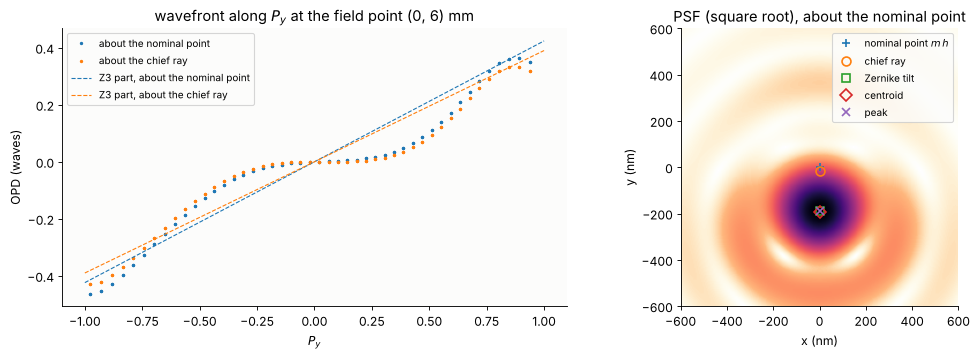

In [4]:
# the PSF from the wavefront about the nominal point (the scalar PSF of the pupil
# P = n' d_xy/NA, uniform amplitude): where is it?
lam_um, NA = lam_C*1e-3, NA_C
k = 2*np.pi/lam_um
x = (np.arange(512) - 256)*lam_um/(4*NA)
X, Y = np.meshgrid(x, x)
phase = lambda Px, Py: 2*np.pi*sum(c*fringe_zernike(j + 1, Px, Py) for j, c in enumerate(c_nom) if j > 0)
I = np.abs(imaging.get_psf(x, x, NA, k, phase=phase))**2
cen = np.array([(I*X).sum(), (I*Y).sum()])/I.sum()*1e3
xo = np.linspace(-0.6, 0.6, 241)                 # zoomed PSF (chirp-z) for the peak and the plot
I_zoom = np.abs(imaging.get_psf(x, x, NA, k, phase=phase, x_out=xo, y_out=xo))**2
XO, YO = np.meshgrid(xo, xo)
peak = np.array([XO.flat[I_zoom.argmax()], YO.flat[I_zoom.argmax()]])*1e3
print("PSF on a grid about the nominal point: centroid ({:.1f}, {:.1f}) nm, peak ({:.0f}, {:.0f}) nm"
      .format(*cen, *peak))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for (W, P), lab, col in [((W_nom, P_nom), "about the nominal point", "C0"),
                         ((W_chf, P_chf), "about the chief ray", "C1")]:
    cut = np.abs(P[:, 0]) < 0.03
    o = np.argsort(P[cut, 1])
    ax.plot(P[cut, 1][o], W[cut][o], ".", ms=4, color=col, label=lab)
pp = np.linspace(-1, 1, 3)
ax.plot(pp, c_nom[2]*pp, "--", color="C0", lw=1, label="Z3 part, about the nominal point")
ax.plot(pp, c_chf[2]*pp, "--", color="C1", lw=1, label="Z3 part, about the chief ray")
ax.set_xlabel("$P_y$"), ax.set_ylabel("OPD (waves)")
ax.set_title("wavefront along $P_y$ at the field point (0, 6) mm")
ax.legend(fontsize=9)
ax = axes[1]
ax.imshow(np.sqrt(I_zoom), extent=[-600, 600, -600, 600], cmap=LIGHT)
for (xx, yy), lab, mk in [((0, 0), "nominal point $m\\,h$", "+"),
                          (dist, "chief ray", "o"),
                          (tilt, "Zernike tilt", "s"),
                          (centroid, "centroid", "D"),
                          (peak, "peak", "x")]:
    ax.plot(xx, yy, mk, ms=8, mfc="none", mew=1.5, label=lab)
ax.set_xlabel("x (nm)"), ax.set_ylabel("y (nm)")
ax.set_title("PSF (square root), about the nominal point")
ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()

- Moving the reference point changes $Z_3$ by exactly the first order amount
  ($-15$ nm of distortion are $0.034$ waves at $\lambda/\mathrm{NA} = 445$ nm)
  and leaves every other coefficient unchanged to $10^{-8}$ waves.
- The surprise is the size of the tilt *about the chief ray*: 0.39 waves,
  170 nm. The wavefront (left) is not a straight line plus small bumps: it is
  flat near the chief ray and steep towards the rim, the shape of
  higher order coma ($Z_8$ = 0.09, $Z_{15}$ = −0.08 waves here). The chief
  ray samples the slope at the centre only, the light as a whole lands
  elsewhere. The chief ray says −15 nm, the Zernike tilt −189 nm, the
  centroid −193 nm, the peak of the PSF lies at about −220 nm (right).
- Which one is "the" distortion depends on what is measured. An
  interferometer measuring the lens over the field reports the Zernike tilt; a
  small isolated feature prints near the centroid; dense patterns sample
  the pupil at a few points only and see yet another weighting (notebook 33).
  For a lens corrected to a few milliwaves of coma the three agree to a few
  nm (the Zeiss design of notebook 33), for Caldwell's lens, which has
  0.1 waves of coma at mid field, they don't.

## 2. Caldwell's lens over the field: magnification and distortion

The lens is rotationally symmetric, so the displacement is radial and a
function $d(h)$ of the image height. Odd polynomials
$d = a_1 h + a_3 h^3 + a_5 h^5 + a_7 h^7$ are fitted to the three versions,
and compared with the third order (Seidel) distortion $S_V$ of
`third_order()` (notebook 44). $a_1$ is a magnification error relative to
the paraxial $m$ (nm per mm = ppm), the $h^3$ term is Hopkins' $W_{311}$.
A scanner sets its magnification to the measured grid, so what matters is
the residual after the best magnification is removed.

In [5]:
H_C = abs(CAL.max_field*m_C) - 1e-3
h = np.linspace(0, H_C, 14)
rad = np.array([[v[1] for v in placements(CAL, (0.0, hh), NA=NA_C)[:3]] for hh in h])   # (h, 3)
th = CAL.third_order()
seidel = th.distortion*h**3/H_C**2*1e6                 # nm, relative distortion ~ h^2
ODD = lambda h, n: np.column_stack([h**(2*i + 1) for i in range(n)])
coef = {lab: np.linalg.lstsq(ODD(h, 4), rad[:, i], rcond=None)[0]
        for i, lab in enumerate(["chief ray", "Zernike tilt", "centroid"])}
print("odd polynomial fits d(h) = a1 h + a3 h^3 + a5 h^5 + a7 h^7 (h in mm, d in nm):")
print("{:13s} {:>10s} {:>14s} {:>14s} {:>14s}".format("", "a1 (ppm)", "a3 h^3 (nm)", "a5 h^5 (nm)",
                                                       "a7 h^7 (nm)"))
for lab, a in coef.items():
    print("{:13s} {:10.2f} {:14.1f} {:14.1f} {:14.1f}".format(lab, a[0], a[1]*H_C**3, a[2]*H_C**5,
                                                              a[3]*H_C**7))
print("Seidel S_V    {:10.2f} {:14.1f}".format(0.0, th.distortion*H_C*1e6))
# what a scanner leaves: the best magnification removed (weighted by the area, ~ h dh)
hh = np.linspace(0, H_C, 400)
resid = {}
for lab, a in coef.items():
    d = ODD(hh, 4) @ a
    m_best = np.sum(hh**2*d)/np.sum(hh**3)
    resid[lab] = (m_best, d - m_best*hh)
    print("{:13s}: best magnification {:6.2f} ppm, residual max |d| {:5.1f} nm".format(
        lab, m_best, np.max(np.abs(d - m_best*hh))))

odd polynomial fits d(h) = a1 h + a3 h^3 + a5 h^5 + a7 h^7 (h in mm, d in nm):
                a1 (ppm)    a3 h^3 (nm)    a5 h^5 (nm)    a7 h^7 (nm)
chief ray           0.14         -188.8          321.0         -213.9
Zernike tilt      -30.36         -285.7          994.5         -387.5
centroid          -25.25         -654.8         1440.8         -563.6
Seidel S_V          0.00         -165.8
chief ray    : best magnification  -4.23 ppm, residual max |d|  30.7 nm
Zernike tilt : best magnification -17.31 ppm, residual max |d| 168.6 nm
centroid     : best magnification -20.19 ppm, residual max |d| 163.2 nm


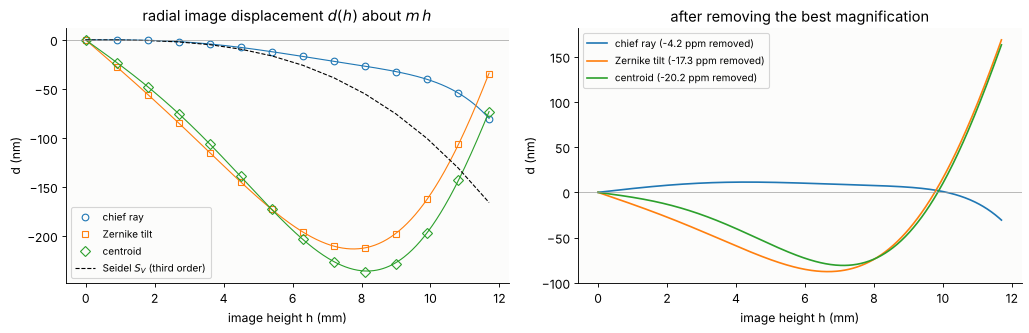

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for i, (lab, mk) in enumerate([("chief ray", "o"), ("Zernike tilt", "s"), ("centroid", "D")]):
    axes[0].plot(h, rad[:, i], mk, color="C%d" % i, mfc="none", label=lab)
    axes[0].plot(hh, ODD(hh, 4) @ coef[lab], color="C%d" % i, lw=1)
    axes[1].plot(hh, resid[lab][1], color="C%d" % i,
                 label="{} ({:+.1f} ppm removed)".format(lab, resid[lab][0]))
axes[0].plot(h, seidel, "k--", lw=1, label="Seidel $S_V$ (third order)")
axes[0].set_title("radial image displacement $d(h)$ about $m\\,h$")
axes[1].set_title("after removing the best magnification")
for ax in axes:
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xlabel("image height h (mm)"), ax.set_ylabel("d (nm)")
    ax.legend(fontsize=9)
plt.tight_layout()

- The **chief ray** distortion of the design is small: below 30 nm everywhere
  after a magnification of −4 ppm is removed. Its third order part ($a_3 h^3$
  = −189 nm at the edge) is close to the Seidel value (−166 nm) and balanced
  by fifth and seventh order terms of opposite sign, the usual way a lens
  designer corrects distortion over a large field.
- The **Zernike tilt** and the **centroid** add the comatic shift of
  section 1. It grows linearly at small fields (coma is linear in the field,
  so its tilt part acts like a magnification of about −30 ppm) and turns
  around towards the edge. After the best magnification (−17 ppm) about
  170 nm are left, far more than any overlay budget: as a lithography lens,
  the design as published would need its coma corrected first.

Because the displacement is radial, the Zernike tilts over the field are
$c_2(x, y) = -\frac{\mathrm{NA}}{\lambda}\,d(r)\,\frac{x}{r}$ and
$c_3(x, y) = -\frac{\mathrm{NA}}{\lambda}\,d(r)\,\frac{y}{r}$: a
magnification is a $Z_2$ that grows linearly with $x$ and a $Z_3$ that grows
linearly with $y$, third order distortion adds $x r^2$ and $y r^2$.

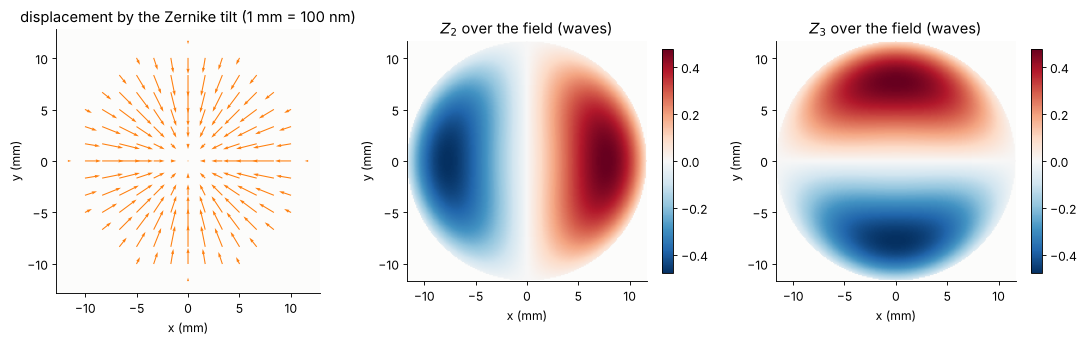

In [7]:
# by rotational symmetry the displacement is radial: d(x, y) = d(r) (x, y)/r; the Zernike
# tilts over the field follow as c2 = -NA/lambda d_x, c3 = -NA/lambda d_y
g = np.linspace(-H_C, H_C, 15)
GX, GY = np.meshgrid(g, g)
R_ = np.hypot(GX, GY)
inside = R_ <= H_C
d_r = np.interp(R_, hh, ODD(hh, 4) @ coef["Zernike tilt"])
with np.errstate(invalid="ignore", divide="ignore"):
    DX, DY = np.where(R_ > 0, d_r*GX/R_, 0), np.where(R_ > 0, d_r*GY/R_, 0)
gf = np.linspace(-H_C, H_C, 201)
FX, FY = np.meshgrid(gf, gf)
RF = np.hypot(FX, FY)
dF = np.interp(RF, hh, ODD(hh, 4) @ coef["Zernike tilt"])
with np.errstate(invalid="ignore", divide="ignore"):
    c2 = np.where(RF <= H_C, -NA_C/lam_C*dF*np.where(RF > 0, FX/RF, 0), np.nan)
    c3 = np.where(RF <= H_C, -NA_C/lam_C*dF*np.where(RF > 0, FY/RF, 0), np.nan)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
axes[0].quiver(GX[inside], GY[inside], DX[inside], DY[inside], angles="xy", scale_units="xy",
               scale=100, width=0.004, color="C1")
axes[0].set_title("displacement by the Zernike tilt (1 mm = 100 nm)")
lim = np.nanmax(np.abs(c3))
for ax, c, lab in [(axes[1], c2, "$Z_2$ over the field (waves)"), (axes[2], c3, "$Z_3$ over the field (waves)")]:
    im = ax.imshow(c, extent=[-H_C, H_C, -H_C, H_C], cmap="RdBu_r", vmin=-lim, vmax=lim)
    plt.colorbar(im, ax=ax, shrink=0.85)
    ax.set_title(lab)
for ax in axes:
    ax.set_aspect("equal"), ax.set_xlabel("x (mm)"), ax.set_ylabel("y (mm)")
plt.tight_layout()

## 3. The vocabulary of grid terms

A lens without errors is rotationally symmetric and can only produce radial
displacements, $d(r)\,\hat{\mathbf r}$: magnification and odd orders of
radial distortion. A real lens, its reticle and its wafer stage add the terms
that overlay metrology fits to every exposure field. Each is a polynomial
displacement field $(d_x, d_y)(x, y)$, and therefore a pair of Zernike tilt
field polynomials $c_2 = -\frac{\mathrm{NA}}{\lambda}d_x$,
$c_3 = -\frac{\mathrm{NA}}{\lambda}d_y$:

| term | $d_x$ | $d_y$ | curl free? | typical origin |
|---|---|---|---|---|
| translation | $1$ | $0$ | yes | reticle or lens decentre |
| magnification | $x$ | $y$ | yes | conjugates, element spacing, wavelength, lens heating |
| anamorphic magnification | $x$ | $-y$ | yes | cylindrical component near the field; in a scanner, the scan speed ratio |
| rotation | $-y$ | $x$ | no | reticle or wafer stage rotation |
| skew (orthogonality) | $y$ | $x$ | yes | $45°$ cylindrical component near the field, stage axes |
| keystone (trapezoid) | $xy$ | $y^2$ | no | tilted reticle or wafer with non telecentric light |
| bow | $y^2$ | $0$ | no | curved scan, bent reticle |
| third order radial | $x r^2$ | $y r^2$ | yes | design residual ($W_{311}$), field-near aspheres |
| fifth order radial | $x r^4$ | $y r^4$ | yes | design residual |

The figure shows each term on a grid (exaggerated). The column *curl free*
matters below: a displacement that is the gradient of a potential can be
produced by a thin phase plate (or freeform surface) in or near the field
plane; rotation, keystone and bow cannot, they need a rotated or tilted
part.

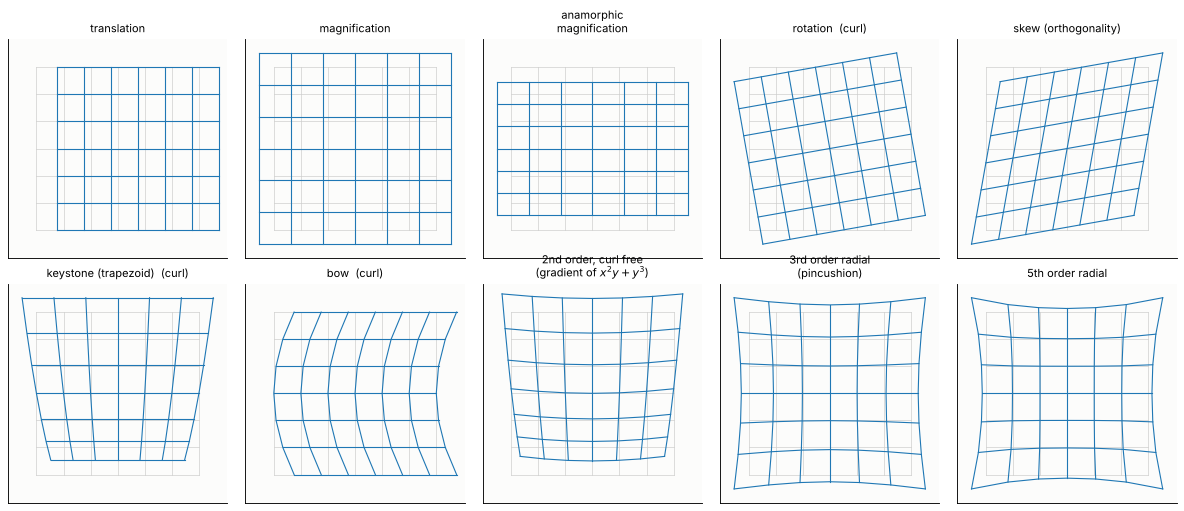

In [8]:
TERMS = [  # name, dx(x, y), dy(x, y), curl free?
    ("translation", lambda x, y: 1 + 0*x, lambda x, y: 0*x),
    ("magnification", lambda x, y: x, lambda x, y: y),
    ("anamorphic\nmagnification", lambda x, y: x, lambda x, y: -y),
    ("rotation", lambda x, y: -y, lambda x, y: x),
    ("skew (orthogonality)", lambda x, y: y, lambda x, y: x),
    ("keystone (trapezoid)", lambda x, y: x*y, lambda x, y: y**2),
    ("bow", lambda x, y: y**2, lambda x, y: 0*x),
    ("2nd order, curl free\n(gradient of $x^2y + y^3$)", lambda x, y: 2*x*y, lambda x, y: x**2 + 3*y**2),
    ("3rd order radial\n(pincushion)", lambda x, y: x*(x**2 + y**2), lambda x, y: y*(x**2 + y**2)),
    ("5th order radial", lambda x, y: x*(x**2 + y**2)**2, lambda x, y: y*(x**2 + y**2)**2),
]
g = np.linspace(-1, 1, 7)
QX, QY = np.meshgrid(g, g)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4))
for ax, (name, fx, fy) in zip(axes.flat, TERMS):
    u, v = fx(QX, QY), fy(QX, QY)
    e = 1e-5
    curl = (fy(QX + e, QY) - fy(QX - e, QY) - fx(QX, QY + e) + fx(QX, QY - e))/(2*e)
    s = np.max(np.hypot(u, v))
    ax.plot(QX, QY, color="0.8", lw=0.6), ax.plot(QX.T, QY.T, color="0.8", lw=0.6)
    ax.plot(QX + 0.25*u/s, QY + 0.25*v/s, color="C0", lw=1.0)
    ax.plot((QX + 0.25*u/s).T, (QY + 0.25*v/s).T, color="C0", lw=1.0)
    ax.set_title(name + ("" if np.allclose(curl, 0, atol=1e-6) else "  (curl)"), fontsize=10)
    ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])
    ax.set_xlim(-1.35, 1.35), ax.set_ylim(-1.35, 1.35)
plt.tight_layout()

For fits the usual tool is the 20 parameter intrafield model: all monomials
up to third order in $x$ and $y$ for $d_x$ and $d_y$, numbered $k_1$ to
$k_{20}$ (odd for $d_x$, even for $d_y$; the numbering differs between
metrology tools). Here every $k$ is the displacement in nm at the edge of
the field (field coordinates normalized to the field radius). The named
first order terms are combinations: magnification $(k_3 + k_4)/2$,
anamorphic $(k_3 - k_4)/2$, rotation $(k_6 - k_5)/2$, skew $(k_5 + k_6)/2$.
A pure third order radial term has $k_{13} = k_{17}$ and $k_{14} = k_{16}$;
Caldwell's chief ray distortion has $k_{13} \ne k_{17}$ because the fifth and
seventh orders of section 2 are folded into the cubic fit.

In [9]:
# the 20 parameter intrafield model, polynomial terms up to third order in x and y
K_TERMS = [("k1", "x", 0, 0), ("k2", "y", 0, 0), ("k3", "x", 1, 0), ("k4", "y", 0, 1),
           ("k5", "x", 0, 1), ("k6", "y", 1, 0), ("k7", "x", 2, 0), ("k8", "y", 0, 2),
           ("k9", "x", 1, 1), ("k10", "y", 1, 1), ("k11", "x", 0, 2), ("k12", "y", 2, 0),
           ("k13", "x", 3, 0), ("k14", "y", 0, 3), ("k15", "x", 2, 1), ("k16", "y", 1, 2),
           ("k17", "x", 1, 2), ("k18", "y", 2, 1), ("k19", "x", 0, 3), ("k20", "y", 3, 0)]


def k_fit(fields, d, scale):
    """Least squares fit of the k model to displacements d (nm) at fields (mm), with the
    field coordinates normalized by `scale` (mm): every k is in nm at the field edge."""
    u = np.asarray(fields)/scale
    out = {}
    for comp, col in (("x", 0), ("y", 1)):
        terms = [t for t in K_TERMS if t[1] == comp]
        A = np.column_stack([u[:, 0]**a*u[:, 1]**b for _, _, a, b in terms])
        c = np.linalg.lstsq(A, d[:, col], rcond=None)[0]
        out.update({t[0]: v for t, v in zip(terms, c)})
    out["rms residual"] = np.sqrt(np.mean((d - k_eval(out, fields, scale))**2))
    return out


def k_eval(k, fields, scale):
    u = np.asarray(fields)/scale
    d = np.zeros((len(u), 2))
    for name, comp, a, b in K_TERMS:
        d[:, 0 if comp == "x" else 1] += k.get(name, 0.0)*u[:, 0]**a*u[:, 1]**b
    return d


def k_names(k):
    """The named combinations of the first order terms (nm at the field edge)."""
    return {"translation": (k["k1"], k["k2"]), "magnification": (k["k3"] + k["k4"])/2,
            "anamorphic": (k["k3"] - k["k4"])/2, "rotation": (k["k6"] - k["k5"])/2,
            "skew": (k["k5"] + k["k6"])/2}


def k_print(k, thr=0.5, label=""):
    big = ", ".join("{} {:+.1f}".format(n, k[n]) for n, *_ in K_TERMS if abs(k[n]) >= thr)
    print("{}{} | rms residual {:.2f} nm".format(label, big or "(all below {} nm)".format(thr),
                                                  k["rms residual"]))


# the field grid: points of the disk of the image field
def disk_grid(radius, n=9):
    g = np.linspace(-radius, radius, n)
    X, Y = np.meshgrid(g, g)
    keep = np.hypot(X, Y) <= radius*1.0001
    return np.column_stack([X[keep], Y[keep]])


FIELD_C = disk_grid(H_C, 9)
d0_C, s0_C = chief(CAL, FIELD_C)
k_print(k_fit(FIELD_C, d0_C, H_C), label="Caldwell, chief ray distortion: ")

Caldwell, chief ray distortion: k3 -7.8, k4 -7.8, k13 -66.9, k14 -66.9, k17 -50.0, k18 -50.0 | rms residual 2.14 nm


## 4. Where grid terms come from: field and pupil

A surface near a **pupil** sees the same footprint from every field point:
whatever it does to the wavefront, it does at all fields alike. A surface near
a **field** (reticle, wafer, intermediate image) sees a small footprint that
moves with the field point: it acts on each field point separately, and
what it does is mostly to *bend the chief ray*, i.e. to move the image. The
paraxial measure is the pupil closeness $|y_m|/(|y_m| + |\bar y|)$ of marginal
and chief ray heights (`pupil_closeness()`, 0 at a field, 1 at a pupil).
In Caldwell's lens the first elements (closeness 0.25 to 0.4) are the most
field-like, the stop region (29 to 38) the most pupil-like.

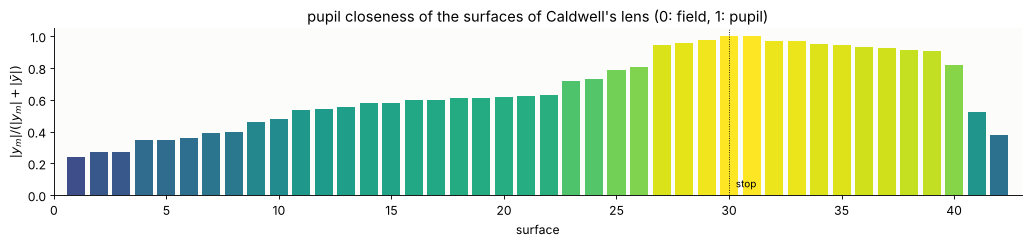

In [10]:
pc = CAL.pupil_closeness()
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(np.arange(1, len(pc) + 1), pc, color=plt.cm.viridis(pc), width=0.8)
ax.axvline(CAL.stop_index + 1, color="k", lw=0.8, ls=":")
ax.text(CAL.stop_index + 1.3, 0.05, "stop", fontsize=9)
ax.set_xlabel("surface"), ax.set_ylabel("$|y_m|/(|y_m| + |\\bar y|)$")
ax.set_title("pupil closeness of the surfaces of Caldwell's lens (0: field, 1: pupil)")
ax.set_xlim(0, len(pc) + 1)
plt.tight_layout()

### Freeform plates near the field

The experiment: a 2 mm fused silica plate 5 mm behind the reticle, its
front surface a Fringe Zernike sag $s = c\,Z_j(x/R, y/R)$ ($R$ = 50 mm,
`ZernikeSurface`). The reference is the same lens with a flat plate,
refocused. The beam from an object point has a footprint of only 0.7 mm
radius on the plate (object side NA 0.14), so the plate acts locally:

- the local **slope** of the sag deflects the chief ray by
  $-(n - 1)\nabla s$; seen from the lens the object point moves by
  $g\,(n - 1)\nabla s$ ($g$ = 5 mm, reticle to plate), and the image by $m$
  times that. The placement map is the *gradient* of the sag map,
- the local **height** of the sag changes the plate thickness and so the
  focus: a field dependent $Z_4$, proportional to $s$ itself,
- the local **curvature** over the small footprint adds a little $Z_5$,
  $Z_6$ and $Z_4$, negligible here.

So near the field, $Z_4$ sag → magnification, $Z_5$ → anamorphic
magnification, $Z_6$ → skew, $Z_9$ → magnification plus third order radial
distortion, $Z_8$ → second order terms (the curl free combination of
keystone and bow, plus a translation). Rotation, keystone and bow alone
cannot be made this way: they have curl. Lithography lenses use exactly such
plates and field-near aspheres to correct the grid of a lens after
assembly.

In [11]:
GAP_PLATE, T_PLATE, R_PLATE = 5.0, 2.0, 50.0     # mm: reticle to plate, plate thickness, norm radius


def with_field_plate(system, zernike):
    """A fused silica plate GAP_PLATE behind the reticle, front surface with the
    Fringe Zernike departure {j: c (mm)}; image plane refocused for the flat plate."""
    o = system.copy()
    front = ZernikeSurface(np.inf, T_PLATE, zernike=zernike, norm_radius=R_PLATE,
                           material=fused_silica, semi_diameter=55.0)
    back = Surface(np.inf, o.object_distance - GAP_PLATE - T_PLATE, n_after=1.0, semi_diameter=55.0)
    o.surfaces = [front, back] + o.surfaces
    o.object_distance = GAP_PLATE
    o.stop_index += 2
    flat = o.copy()
    flat.surfaces[0] = Surface(np.inf, T_PLATE, material=fused_silica, semi_diameter=55.0)
    return o.with_image_distance(flat.paraxial().image_distance)


def with_pupil_freeform(system, zernike, index=None, norm_radius=70.0):
    """The stop surface with a Fringe Zernike departure {j: c (mm)}."""
    o = system.copy()
    index = o.stop_index if index is None else index
    s = o.surfaces[index]
    o.surfaces[index] = ZernikeSurface(s.R, s.thickness, zernike=zernike, norm_radius=norm_radius,
                                       n_after=s.n_after, material=s.material,
                                       semi_diameter=s.semi_diameter)
    return o


n_fs = fused_silica(CAL.wavelength*1e6)
ref_plate = with_field_plate(CAL, {})
m_plate = ref_plate.paraxial().magnification
d_ref, _ = chief(ref_plate, FIELD_C, m_plate)
print("flat plate: n = {:.4f}, m = {:.7f}".format(n_fs, m_plate))


def predicted(fields, j, c):
    """First order: the plate deflects the chief ray by -(n - 1) grad s, the object
    point appears shifted by GAP_PLATE (n - 1) grad s, the image by m times that (nm)."""
    obj = np.asarray(fields)/m_plate
    h = 1e-4
    u, v = obj[:, 0]/R_PLATE, obj[:, 1]/R_PLATE
    gx = (fringe_zernike(j, u + h, v) - fringe_zernike(j, u - h, v))/(2*h)/R_PLATE
    gy = (fringe_zernike(j, u, v + h) - fringe_zernike(j, u, v - h))/(2*h)/R_PLATE
    return m_plate*GAP_PLATE*(n_fs - 1)*c*np.column_stack([gx, gy])*1e6


PLATES = [(4, 5e-3), (5, 5e-3), (6, 5e-3), (9, 1e-3), (8, 2e-3)]
plate_results = {}
for j, c in PLATES:
    sys_j = with_field_plate(CAL, {j: c})
    dd = chief(sys_j, FIELD_C, m_plate)[0] - d_ref
    plate_results[j] = (sys_j, dd)
    kk = k_fit(FIELD_C, dd, H_C)
    print("Z{} sag {:.0f} um: traced vs first order prediction, rms difference {:.1f} nm of {:.1f} nm"
          .format(j, c*1e3, np.sqrt(np.mean((dd - predicted(FIELD_C, j, c))**2)),
                  np.sqrt(np.mean(dd**2))))
    k_print(kk, thr=1.0, label="    ")

flat plate: n = 1.5084, m = -0.2500150


Z4 sag 5 um: traced vs first order prediction, rms difference 0.2 nm of 117.9 nm
    k3 +238.0, k4 +238.0 | rms residual 0.15 nm


Z5 sag 5 um: traced vs first order prediction, rms difference 0.2 nm of 58.9 nm
    k3 +118.4, k4 -118.4, k13 +1.2 | rms residual 0.10 nm


Z6 sag 5 um: traced vs first order prediction, rms difference 0.1 nm of 58.9 nm
    k5 +118.6, k6 +118.6 | rms residual 0.06 nm


Z9 sag 1 um: traced vs first order prediction, rms difference 0.0 nm of 31.7 nm
    k3 -142.8, k4 -142.8, k13 +250.2, k14 +250.2, k17 +250.1, k18 +250.1 | rms residual 0.02 nm


Z8 sag 2 um: traced vs first order prediction, rms difference 0.0 nm of 39.5 nm
    k2 +50.8, k8 -200.4, k9 -133.6, k12 -66.7 | rms residual 0.04 nm


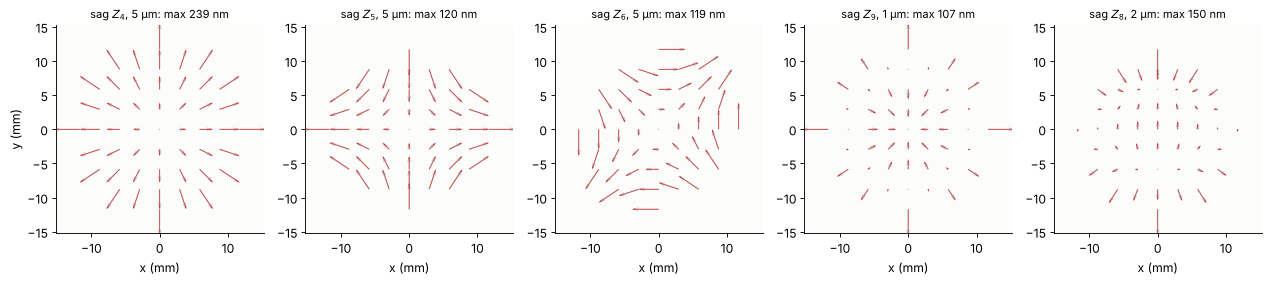

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, (j, c) in zip(axes, PLATES):
    dd = plate_results[j][1]
    pr = predicted(FIELD_C, j, c)
    sc = 3*np.max(np.hypot(dd[:, 0], dd[:, 1]))/H_C
    ax.quiver(FIELD_C[:, 0], FIELD_C[:, 1], pr[:, 0], pr[:, 1], angles="xy", scale_units="xy",
              scale=sc, width=0.006, color="0.75")
    ax.quiver(FIELD_C[:, 0], FIELD_C[:, 1], dd[:, 0], dd[:, 1], angles="xy", scale_units="xy",
              scale=sc, width=0.003, color="C3")
    ax.set_title("sag $Z_{{{}}}$, {:.0f} µm: max {:.0f} nm".format(j, c*1e3,
                 np.max(np.hypot(dd[:, 0], dd[:, 1]))), fontsize=10)
    ax.set_aspect("equal"), ax.set_xlabel("x (mm)")
    ax.set_xlim(-1.3*H_C, 1.3*H_C), ax.set_ylim(-1.3*H_C, 1.3*H_C)
axes[0].set_ylabel("y (mm)")
plt.tight_layout()

The traced displacements (red) agree with the first order prediction
(grey, under the red arrows) to 0.2 nm, and the $k$ fits contain only the
expected terms: $k_3 = k_4$ for $Z_4$, $k_3 = -k_4$ for $Z_5$, $k_5 = k_6$ for
$Z_6$, $k_3 = k_4$ together with $k_{13} = k_{14} = k_{17} = k_{18}$ for $Z_9$.

### The same sag near the pupil

Now the same $Z_5$ shape on the stop surface (surface 30), 100 times weaker
(50 nm sag). Near the pupil the sag *is* the wavefront: $(n - 1)\,s$ of OPD,
0.1 waves of $Z_5$, at every field point. The chief ray goes through the
centre of the stop where $Z_5$ has no slope, so nothing moves.

In [13]:
# the same Z5 departure (scaled) near the pupil: astigmatism everywhere, no anamorphism
pupil_sys = with_pupil_freeform(CAL, {5: 5e-5})
d_pup = chief(pupil_sys, FIELD_C)[0] - d0_C
k_print(k_fit(FIELD_C, d_pup, H_C), thr=0.2, label="Z5 at the stop, 50 nm sag: ")
LINE = np.column_stack([np.zeros(7), np.linspace(-H_C, H_C, 7)])
LINE = np.vstack([LINE, LINE[:, ::-1]])
z5 = {"lens": [], "field plate (Z5, 5 µm)": [], "stop (Z5, 50 nm)": []}
NA_ref = lens_NA(CAL)
for f in LINE:
    z5["lens"].append(lens_aberrations(CAL, f, n_terms=16, NA=NA_ref).zernikes)
    z5["field plate (Z5, 5 µm)"].append(lens_aberrations(plate_results[5][0], f, n_terms=16,
                                                         NA=NA_ref).zernikes)
    z5["stop (Z5, 50 nm)"].append(lens_aberrations(pupil_sys, f, n_terms=16, NA=NA_ref).zernikes)
ref_flat = [lens_aberrations(ref_plate, f, n_terms=16, NA=NA_ref).zernikes for f in LINE]

Z5 at the stop, 50 nm sag: (all below 0.2 nm) | rms residual 0.00 nm


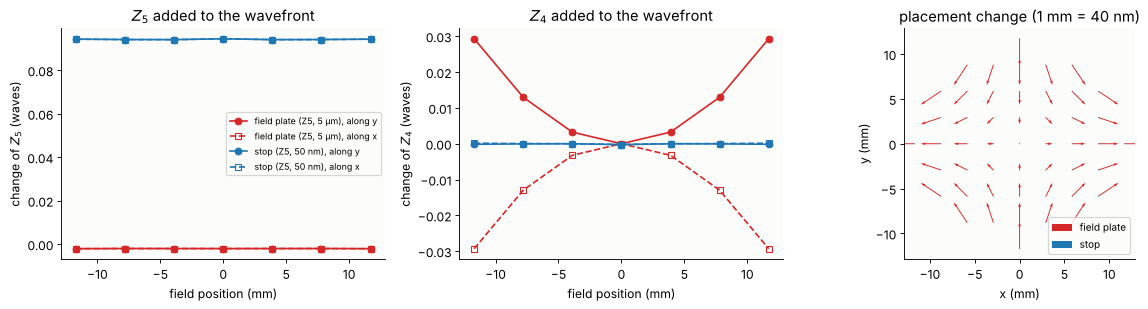

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
pos = np.r_[LINE[:7, 1], LINE[7:, 0]]
for ax, j in zip(axes[:2], (5, 4)):
    for lab, base, col in [("field plate (Z5, 5 µm)", ref_flat, "C3"),
                           ("stop (Z5, 50 nm)", z5["lens"], "C0")]:
        dz = np.array([a[j] - b[j] for a, b in zip(z5[lab], base)])
        ax.plot(pos[:7], dz[:7], "o-", color=col, label=lab + ", along y")
        ax.plot(pos[7:], dz[7:], "s--", color=col, mfc="none", label=lab + ", along x")
    ax.set_xlabel("field position (mm)"), ax.set_ylabel("change of $Z_{%d}$ (waves)" % j)
    ax.set_title("$Z_{%d}$ added to the wavefront" % j)
axes[0].legend(fontsize=8)
for lab, dd, col in [("field plate", plate_results[5][1], "C3"), ("stop", d_pup, "C0")]:
    axes[2].quiver(FIELD_C[:, 0], FIELD_C[:, 1], dd[:, 0], dd[:, 1], angles="xy",
                   scale_units="xy", scale=40, width=0.004, color=col, label=lab)
axes[2].set_title("placement change (1 mm = 40 nm)")
axes[2].set_aspect("equal"), axes[2].legend(fontsize=9, loc="lower right")
axes[2].set_xlabel("x (mm)"), axes[2].set_ylabel("y (mm)")
plt.tight_layout()

Left: the stop freeform gives 0.094 waves of $Z_5$ at every field point;
the field plate, with a 100 times larger sag, gives 0.002 waves. Middle: the
field plate changes the focus over the field instead ($Z_4 \propto s$:
$+$ along $y$ and $-$ along $x$, 0.03 waves at the edge, from the
thickness change of the plate), the stop freeform does not. Right: the
field plate gives 120 nm of anamorphic magnification, the stop freeform less
than 0.2 nm of anything. The same Zernike shape is a wavefront aberration
near the pupil and a grid term (plus a focus map) near the field.

### Element shifts: the manipulators of a lens

Scanners adjust their lenses during operation (lens heating, wavelength,
pressure) by moving a few elements along the axis. Each element of
Caldwell's lens is moved by 10 µm, and the change of magnification and
third order distortion is compared with the change of $Z_4$ and $Z_9$ on
axis. The reticle is moved too.

In [15]:
# manipulators: every element moved 10 um along the axis (and the reticle)
DZ = 0.010
H6 = np.column_stack([np.zeros(6), np.linspace(0, H_C, 6)])
d_base = chief(CAL, H6, m_C)[0][:, 1]
z_base = CAL.zernike(0.0, n_terms=16, N=48)
rows = []
for e, (a, b) in enumerate(CAL.elements()):
    s = CAL.with_axial_shift(a, b, DZ)
    dd = chief(s, H6, m_C)[0][:, 1] - d_base
    k1, k3 = np.linalg.lstsq(ODD(H6[:, 1], 2), dd, rcond=None)[0]
    dzern = s.zernike(0.0, n_terms=16, N=48) - z_base
    rows.append((e + 1, np.mean(pc[[a, b]]), k1, k3*H_C**3, dzern[3], dzern[8]))
s = CAL.copy()
s.object_distance += DZ
dd = chief(s, H6, m_C)[0][:, 1] - d_base
k1, k3 = np.linalg.lstsq(ODD(H6[:, 1], 2), dd, rcond=None)[0]
dzern = s.zernike(0.0, n_terms=16, N=48) - z_base
rows.append(("reticle", 0.0, k1, k3*H_C**3, dzern[3], dzern[8]))
rows_a = np.array([r[1:] for r in rows], dtype=float)
print("{:>8s} {:>9s} {:>11s} {:>12s} {:>10s} {:>10s}".format("element", "closeness", "mag (ppm)",
                                                                "D3 edge (nm)", "Z4 (mλ)", "Z9 (mλ)"))
for r in rows:
    print("{:>8} {:9.2f} {:11.2f} {:12.2f} {:10.0f} {:10.1f}".format(r[0], r[1], r[2], r[3],
                                                                     r[4]*1e3, r[5]*1e3))

 element closeness   mag (ppm) D3 edge (nm)    Z4 (mλ)    Z9 (mλ)
       1      0.25       12.45        15.12        -81       -2.9
       2      0.31        0.08        -7.81       -105       -3.9
       3      0.35        6.98         0.27         40        1.5
       4      0.40       -3.89         7.85        176        7.3
       5      0.47      -16.47         6.45        274       16.3
       6      0.54     -153.36      -165.17       1928      118.5
       7      0.57      115.59       103.83      -1516      -92.4
       8      0.59       43.79        54.66       -809      -48.9
       9      0.60       -8.09         1.46       -103       -1.5
      10      0.62      -26.45        -8.31        139       12.2
      11      0.63      -55.06        -0.98        440       28.8
      12      0.73       83.59         7.22       -582      -41.9
      13      0.80       32.23         6.29        373       19.9
      14      0.95       46.09         8.10       3286      300.4
      15  

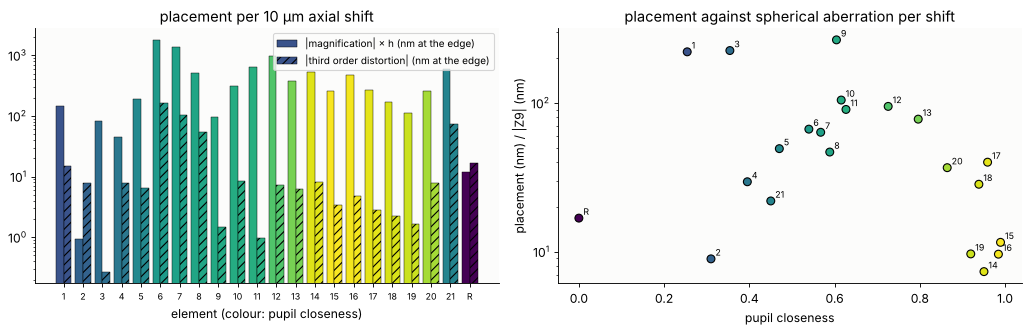

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
labels = [str(r[0]) if r[0] != "reticle" else "R" for r in rows]
x_ = np.arange(len(rows))
cols = plt.cm.viridis(rows_a[:, 0])
axes[0].bar(x_ - 0.2, np.abs(rows_a[:, 1])*H_C, width=0.4, color=cols, edgecolor="k", lw=0.4,
            label="|magnification| × h (nm at the edge)")
axes[0].bar(x_ + 0.2, np.abs(rows_a[:, 2]), width=0.4, color=cols, hatch="///", edgecolor="k",
            lw=0.4, label="|third order distortion| (nm at the edge)")
axes[0].set_yscale("log"), axes[0].set_xticks(x_, labels, fontsize=8)
axes[0].set_xlabel("element (colour: pupil closeness)"), axes[0].legend(fontsize=9)
axes[0].set_title("placement per 10 µm axial shift")
ratio = (np.abs(rows_a[:, 1])*H_C + np.abs(rows_a[:, 2]))/(np.abs(rows_a[:, 4])*lam_C)
axes[1].scatter(rows_a[:, 0], ratio, c=cols, edgecolor="k", s=50)
for (xx, yy, lab) in zip(rows_a[:, 0], ratio, labels):
    axes[1].annotate(lab, (xx, yy), textcoords="offset points", xytext=(4, 3), fontsize=8)
axes[1].set_yscale("log")
axes[1].set_xlabel("pupil closeness"), axes[1].set_ylabel("placement (nm) / |Z9| (nm)")
axes[1].set_title("placement against spherical aberration per shift")
plt.tight_layout()

- Every element changes the magnification, by up to 150 ppm per 10 µm
  (element 6, the strong negative element at the first waist, surfaces 11/12
  with R = −82 mm). These are large numbers: magnification is controlled to
  well below 1 ppm.
- What distinguishes the elements is what else they change. The elements
  near the stop (14 to 19, pupil closeness above 0.9) give 7 to 40 nm of
  placement per nm of spherical aberration, most elements of the front part
  (1 to 13) 50 to 270; the exceptions (2, 4) are elements that happen to
  leave the magnification almost unchanged. A
  manipulator for magnification and distortion sits near the field, one for
  spherical aberration near the pupil, and a set of a few of each can be
  solved for any combination (the same logic as notebook 44, with real
  rays).
- Moving the **reticle** by 10 µm changes the magnification by only 1 ppm:
  the lens is telecentric on the object side, so the chief rays leave the
  reticle parallel to the axis and the image size does not depend on the
  reticle height. It moves the focus ($m^2 \cdot 10$ µm = 0.6 µm, $Z_4$ =
  −0.2 waves) and, because the object side telecentricity is not perfect
  over the field, adds 17 nm of third order distortion.

## 5. Telecentricity: the centroid of the pupil

### The theorem

Take the scalar field in the image space as an angular spectrum
$U(\mathbf x, z) = \int A(\mathbf k_\perp)\,e^{i(\mathbf k_\perp\cdot\mathbf x + k_z z)}\,d^2k_\perp$.
Its intensity centroid moves along $z$ in a straight line,

$$\frac{d\langle\mathbf x\rangle}{dz} = \left\langle\frac{\mathbf k_\perp}{k_z}\right\rangle_{|A|^2}
\approx \frac{\mathrm{NA}}{n'}\,\langle\mathbf P\rangle_{|A|^2},$$

the power weighted mean of the plane wave slopes, whatever the phase of
$A$. Aberrations (phase) move the centroid sideways once, by
$-\frac{\lambda}{\mathrm{NA}}\langle\nabla W\rangle$; only the distribution of
*power* over the pupil makes it drift through focus. In Zernike language:
defocus by $z$ is $c_4 = -\mathrm{NA}^2 z/(4\lambda)$ (paraxially), its
gradient $4 c_4\mathbf P$, so through focus the effective tilt is

$$c_{2,\mathrm{eff}} = c_2 + 4\,c_4\,\langle P_x\rangle, \qquad
\langle P_x\rangle = \frac{a_2}{4\,a_1}\ \text{for an intensity}\ I(\mathbf P) = \sum_j a_j Z_j,$$

since $Z_2$ is the only Fringe term not orthogonal to $P_x$. A telecentric
image has $\langle\mathbf P\rangle = 0$ in pupil coordinates about the axis.
It is lost by a **decentred pupil** (the light cone tilted as a whole: the
chief ray, or pupil aberrations that shift the cone against the chief ray)
or by an **intensity tilt** (apodization by coatings, absorption, or the
illumination). A toy check with the scalar PSF of `imaging.get_psf()` (NA
0.56, 248 nm, the defocus as the exact $k_z z$):

In [17]:
# the theorem on a toy pupil: scalar angular spectrum, PSF centroid through focus
lam_t, NA_t, n_t = 0.2483, 0.56, 1.0          # um
k_t = 2*np.pi/lam_t
NA_grid = 0.7                                  # pupil grid big enough for the decentred disk
xt = (np.arange(512) - 256)*lam_t/(4*NA_grid)
XT, YT = np.meshgrid(xt, xt)
zs = np.linspace(-1.0, 1.0, 5)                 # um
r = NA_t/NA_grid                               # radius of the lens pupil on the grid


def disk(Px, Py, dx=0.0):
    return ((Px/r - dx)**2 + (Py/r)**2 <= 1).astype(float)


TOY = {
    "coma $Z_7$ = 0.1 λ": (lambda Px, Py: disk(Px, Py),
                          lambda Px, Py: 2*np.pi*0.1*fringe_zernike(7, Px/r, Py/r)),
    "intensity tilt $1 + 0.4\\,P_x$": (lambda Px, Py: disk(Px, Py)*np.sqrt(np.clip(1 + 0.4*Px/r, 0, None)),
                                      None),
    "pupil decentred by 0.1": (lambda Px, Py: disk(Px, Py, 0.1), None),
}
toy = {}
for name, (amp, ph) in TOY.items():
    cx = []
    for z in zs:
        def phase(Px, Py, z=z):
            kz = k_t*np.sqrt(np.clip(n_t**2 - (NA_grid*Px)**2 - (NA_grid*Py)**2, 0, None))
            return kz*z + (ph(Px, Py) if ph else 0.0)
        I = np.abs(imaging.get_psf(xt, xt, NA_grid, k_t, pupil_mask=amp, phase=phase))**2
        cx.append((I*XT).sum()/I.sum())
    # prediction: the power weighted mean of k_x/k_z over the pupil
    Px, Py = imaging.pupil_coordinates(xt, xt, NA_grid, k_t)
    w = np.abs(amp(Px, Py))**2*(Px**2 + Py**2 <= 1)
    kx, kz = NA_grid*Px, np.sqrt(np.clip(n_t**2 - (NA_grid*Px)**2 - (NA_grid*Py)**2, 1e-12, None))
    toy[name] = (np.array(cx), np.sum(w*kx/kz)/np.sum(w), np.sum(w*kx)/np.sum(w), w)
    print("{:30s}: centroid slope {:7.4f}, <k_x/k_z> {:7.4f}, <sin theta_x> {:7.4f}".format(
        name.replace("$", ""), np.polyfit(zs, cx, 1)[0], toy[name][1], toy[name][2]))

coma Z_7 = 0.1 λ              : centroid slope -0.0000, <k_x/k_z> -0.0000, <sin theta_x> -0.0000
intensity tilt 1 + 0.4\,P_x   : centroid slope  0.0626, <k_x/k_z>  0.0632, <sin theta_x>  0.0560
pupil decentred by 0.1        : centroid slope  0.0675, <k_x/k_z>  0.0678, <sin theta_x>  0.0560


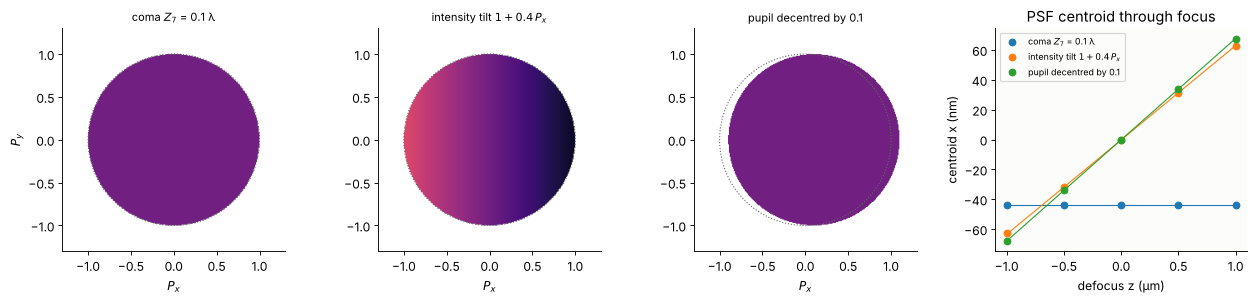

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (name, (cx, slope, _, w)) in zip(axes[:3], toy.items()):
    sel = np.abs(xt) < 1
    Pg = imaging.pupil_coordinates(xt, xt, NA_grid, k_t)[0][0]/r
    ax.imshow(w, extent=[Pg[0], Pg[-1], Pg[0], Pg[-1]], cmap=LIGHT, vmin=0, vmax=1.5)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.4", ls=":"))
    ax.set_xlim(-1.3, 1.3), ax.set_ylim(-1.3, 1.3)
    ax.set_title(name, fontsize=10), ax.set_xlabel("$P_x$")
for i, (name, (cx, slope, _, w)) in enumerate(toy.items()):
    axes[3].plot(zs, cx*1e3, "o", color="C%d" % i, label=name)
    axes[3].plot(zs, (cx[2] + slope*zs)*1e3, color="C%d" % i, lw=1)
axes[3].set_xlabel("defocus z (µm)"), axes[3].set_ylabel("centroid x (nm)")
axes[3].set_title("PSF centroid through focus"), axes[3].legend(fontsize=8)
axes[0].set_ylabel("$P_y$")
plt.tight_layout()

Coma alone moves the centroid by $-0.1\,\lambda/\mathrm{NA} = -44$ nm and
keeps it there at every focus. An intensity tilt $1 + 0.4 P_x$ ($a_2/a_1 =$
0.4, $\langle P_x\rangle = 0.1$) and a pupil decentred by 0.1 both make the
centroid drift, by 63 and 68 mrad, as predicted by $\langle k_x/k_z\rangle$
(the paraxial $\mathrm{NA}\langle P_x\rangle = 56$ mrad underestimates the
rim rays, whose slope is $\tan\theta$, not $\sin\theta$).

### Two real lenses over the field

`lens_telecentricity()` weights the image side ray slopes with the
etendue of the ray tubes, the illumination fill and the transmission of the
polarization ray trace (notebook 41). Three cases: the chief ray, the whole
cone that the stop passes (a point source: what a small isolated feature or
the PSF sees) and a conventional illumination with $\sigma = 0.5$ (what the
zero order of a large feature sees). The right axis converts the slope to
the pupil centroid $\langle P_y\rangle$.

In [19]:
# real lenses: chief ray against the centroid of the light over the field
tele = {}
for name, lens, H in [("Caldwell KrF", CAL, H_C), ("Zeiss ArFi", ZEI, abs(ZEI.max_field*ZEI.paraxial().magnification) - 1e-3)]:
    hs = np.linspace(0, H, 8)
    rows_t = []
    for hh_ in hs:
        cone = lens_telecentricity(lens, (0.0, hh_))
        conv = lens_telecentricity(lens, (0.0, hh_), fill=0.5)
        rows_t.append((cone.chief[1], cone.energetic[1], conv.energetic[1]))
    tele[name] = (hs, np.array(rows_t), lens)
    print(name, "edge of the field: chief {:.1f} mrad, whole cone {:.1f} mrad, sigma 0.5 {:.1f} mrad"
          .format(*(np.array(rows_t[-1])*1e3)))

Caldwell KrF edge of the field: chief -2.9 mrad, whole cone -45.1 mrad, sigma 0.5 -3.1 mrad


Zeiss ArFi edge of the field: chief 40.2 mrad, whole cone 11.2 mrad, sigma 0.5 46.0 mrad


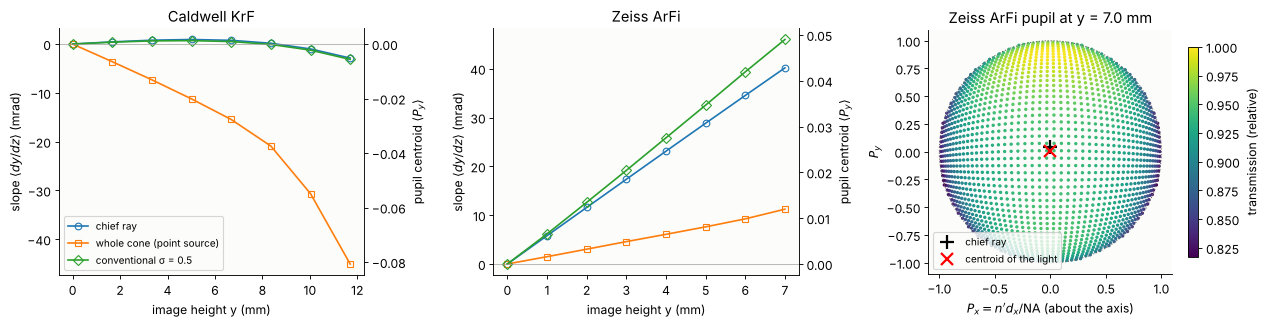

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, (hs, tt, lens)) in zip(axes[:2], tele.items()):
    for i, (lab, mk) in enumerate([("chief ray", "o-"), ("whole cone (point source)", "s-"),
                                   ("conventional σ = 0.5", "D-")]):
        ax.plot(hs, tt[:, i]*1e3, mk, color="C%d" % i, mfc="none", label=lab)
    ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xlabel("image height y (mm)"), ax.set_ylabel("slope $\\langle dy/dz \\rangle$ (mrad)")
    ax.set_title(name)
    na = lens_NA(lens)
    sec = ax.secondary_yaxis("right", functions=(lambda t, na=na, n=lens.n[-1]: t*1e-3*n/na,
                                                 lambda P, na=na, n=lens.n[-1]: P*na/n*1e3))
    sec.set_ylabel("pupil centroid $\\langle P_y \\rangle$")
axes[0].legend(fontsize=9)
# the pupil (support and etendue weighting) of the Zeiss lens at the edge of the field
H_Z = tele["Zeiss ArFi"][0][-1]
NA_Z = lens_NA(ZEI)
cone = lens_telecentricity(ZEI, (0.0, H_Z))
s_edge = chief(ZEI, [(0.0, H_Z)])[1][0]
P_chief = ZEI.n[-1]*s_edge/np.sqrt(1 + s_edge @ s_edge)/NA_Z      # n' d_xy/NA of the chief ray
sc = axes[2].scatter(cone.P_x + P_chief[0], cone.P_y + P_chief[1], c=cone.T/cone.T.max(),
                     s=4, cmap="viridis")
axes[2].add_patch(plt.Circle((0, 0), 1, fill=False, color="0.4", ls=":"))
axes[2].plot(*P_chief, "k+", ms=12, mew=2, label="chief ray")
wT = cone.weight*cone.T
cen = np.array([np.sum(wT*(cone.P_x + P_chief[0])), np.sum(wT*(cone.P_y + P_chief[1]))])/np.sum(wT)
axes[2].plot(*cen, "rx", ms=10, mew=2, label="centroid of the light")
plt.colorbar(sc, ax=axes[2], shrink=0.85, label="transmission (relative)")
axes[2].set_aspect("equal"), axes[2].legend(fontsize=9, loc="lower left")
axes[2].set_xlabel("$P_x = n' d_x/\\mathrm{NA}$ (about the axis)"), axes[2].set_ylabel("$P_y$")
axes[2].set_title("Zeiss ArFi pupil at y = {:.1f} mm".format(H_Z))
plt.tight_layout()

- **Caldwell**: the chief rays are telecentric to 3 mrad, and so is the
  light of a $\sigma = 0.5$ illumination. The whole cone, though, leans by
  up to −45 mrad at the edge: seen from an off-axis object point, the stop
  is not centred on the chief ray (pupil coma of the front group, notebook
  41), the cone is shifted by 8 % of the pupil radius.
- **Zeiss ArFi**: the chief ray is tilted outwards in proportion to the field
  (40 mrad at 7 mm, a "magnification through focus"), the $\sigma = 0.5$ light
  follows it (46 mrad), but the whole cone leans by only 11 mrad. The right
  panel shows why: at the edge of the field the real pupil (the support of
  the traced rays, in coordinates about the axis) is centred on the axis,
  not on the chief ray at $P_y = 0.04$; with the etendue weighting alone the
  cone is telecentric to 0.5 mrad. The 11 mrad that remain are an intensity
  tilt: the transmission of the uncoated surfaces (the default here) rises
  towards $+P_y$, an apodization $Z_3$ of the intensity with
  $a_3/a_1 \approx 4\langle P_y\rangle \approx 0.05$.

So a lens has no single telecentricity: it is a property of the light, set by
which part of the pupil a pattern uses. The chief ray is the special case of
a narrow cone about the centre of the stop.

### A wave optical check

At the edge of the Zeiss field: the PSF through focus from the real pupil
(`lens_apodization()`: the support of the traced rays and their
transmission, on a grid 10 % larger than the NA) and the phase of the 36
Zernikes of `lens_aberrations()`, propagated with the exact $k_z$ of the
absolute directions in the water.

In [21]:
# wave check at the edge of the Zeiss field: PSF centroid through focus from the real pupil
ab_Z = lens_aberrations(ZEI, (0.0, H_Z), n_terms=36, NA=NA_Z)
NA_grid = 1.1*NA_Z
apod = lens_apodization(ZEI, (0.0, H_Z), NA=NA_grid)
n_w = ZEI.n[-1]
lam_Z = ZEI.wavelength*1e3       # um
k_Z = 2*np.pi/lam_Z
xz = (np.arange(512) - 256)*lam_Z/(4*NA_grid)
XZ, YZ = np.meshgrid(xz, xz)
s_chief = chief(ZEI, [(0.0, H_Z)])[1][0]
zz = np.linspace(-0.4, 0.4, 5)    # um
cy = []
for z in zz:
    def phase(Px, Py, z=z):
        Pu, Pv = Px*NA_grid/NA_Z, Py*NA_grid/NA_Z          # on the lens_aberrations pupil
        W = sum(c*fringe_zernike(j, Pu, Pv) for j, c in ab_Z.zernikes.items())
        # angular spectrum about the chief ray direction: k_z of the absolute direction
        sx = NA_grid*Px + n_w*s_chief[0]/np.sqrt(1 + s_chief @ s_chief)
        sy = NA_grid*Py + n_w*s_chief[1]/np.sqrt(1 + s_chief @ s_chief)
        kz = k_Z*np.sqrt(np.clip(n_w**2 - sx**2 - sy**2, 0, None))
        return 2*np.pi*W + kz*z
    I = np.abs(imaging.get_psf(xz, xz, NA_grid, k_Z, pupil_mask=apod, phase=phase))**2
    cy.append((I*YZ).sum()/I.sum())
cy = np.array(cy)
slope = np.polyfit(zz, cy, 1)[0]
# k_z of the absolute directions: the grid x, y is the fixed image plane
print("Zeiss ArFi at y = {:.2f} mm: PSF centroid moves by {:.1f} mrad through focus".format(H_Z, slope*1e3))
print("ray traced: chief ray {:.1f} mrad, centroid of the whole cone {:.1f} mrad"
      .format(s_chief[1]*1e3, cone.energetic[1]*1e3))

Zeiss ArFi at y = 7.00 mm: PSF centroid moves by 11.0 mrad through focus
ray traced: chief ray 40.2 mrad, centroid of the whole cone 11.2 mrad


The PSF centroid drifts by 11.0 mrad, the ray traced centroid of the whole
cone is 11.2 mrad, the chief ray 40 mrad. A contact hole printed at the edge
of the field moves through focus with the centroid of its light, not with the
chief ray.

### Telecentricity turns focus into grid terms

With a telecentricity map $\mathbf t(x, y)$ the placement at a height $z$
above the best focus plane is $\mathbf d(x, y, z) = \mathbf d_0(x, y) + z\,\mathbf t(x, y)$.
Defocus, wafer tilt and wafer topography therefore print as grid terms:

- uniform **defocus** $z$ with a radial $\mathbf t = t_1\,(x, y)$ (Zeiss: $t_1$ =
  5.7 mrad/mm) is a **magnification** $z t_1$,
- a **wafer tilt** $z = \beta y$ gives $\beta t_1(xy, y^2)$, a **keystone**,
- a curved wafer or field curvature, $z \propto r^2$, gives **third order
  radial distortion**.

The chief ray maps of both lenses, for 100 nm of defocus and a wafer tilt of
20 µrad (100 nm over 5 mm), fitted with the $k$ model; the defocus case is
checked against rays traced into a shifted image plane.

In [22]:
# telecentricity turns focus and wafer height into grid terms: d(x, y, z) = d0 + z t(x, y)
FIELD_Z = disk_grid(H_Z, 9)
d0_Z, t_Z = chief(ZEI, FIELD_Z)
t_C = s0_C
cases = {}
for name, field, tt, H, lens in [("Caldwell KrF", FIELD_C, t_C, H_C, CAL),
                                 ("Zeiss ArFi", FIELD_Z, t_Z, H_Z, ZEI)]:
    dz_focus = 100e-6                                   # 100 nm defocus (mm)
    focus = dz_focus*tt*1e6                             # nm
    beta = 20e-6                                        # wafer tilt about x (rad)
    tilt = (beta*field[:, 1])[:, None]*tt*1e6
    # check against rays traced into the shifted and the tilted image plane
    m_l = lens.paraxial().magnification
    sh = lens.with_image_distance(lens.surfaces[-1].thickness + dz_focus)
    d_sh = chief(sh, field, m_l)[0] - chief(lens, field, m_l)[0]
    cases[name] = (field, H, focus, tilt, d_sh, k_fit(field, focus, H), k_fit(field, tilt, H))
    print(name)
    print("  100 nm defocus, traced vs z t: max difference {:.3f} nm".format(np.max(np.abs(d_sh - focus))))
    k_print(cases[name][5], thr=0.05, label="  100 nm defocus:      ")
    k_print(cases[name][6], thr=0.05, label="  20 µrad wafer tilt:  ")

Caldwell KrF
  100 nm defocus, traced vs z t: max difference 0.000 nm
  100 nm defocus:      k3 +0.3, k4 +0.3, k13 -0.6, k14 -0.6, k17 -0.6, k18 -0.6 | rms residual 0.00 nm
  20 µrad wafer tilt:  k2 +0.1, k8 -0.5, k9 -0.2, k12 -0.2 | rms residual 0.07 nm


Zeiss ArFi
  100 nm defocus, traced vs z t: max difference 0.000 nm
  100 nm defocus:      k3 +4.1, k4 +4.1 | rms residual 0.00 nm
  20 µrad wafer tilt:  k8 +5.6, k9 +5.6 | rms residual 0.00 nm


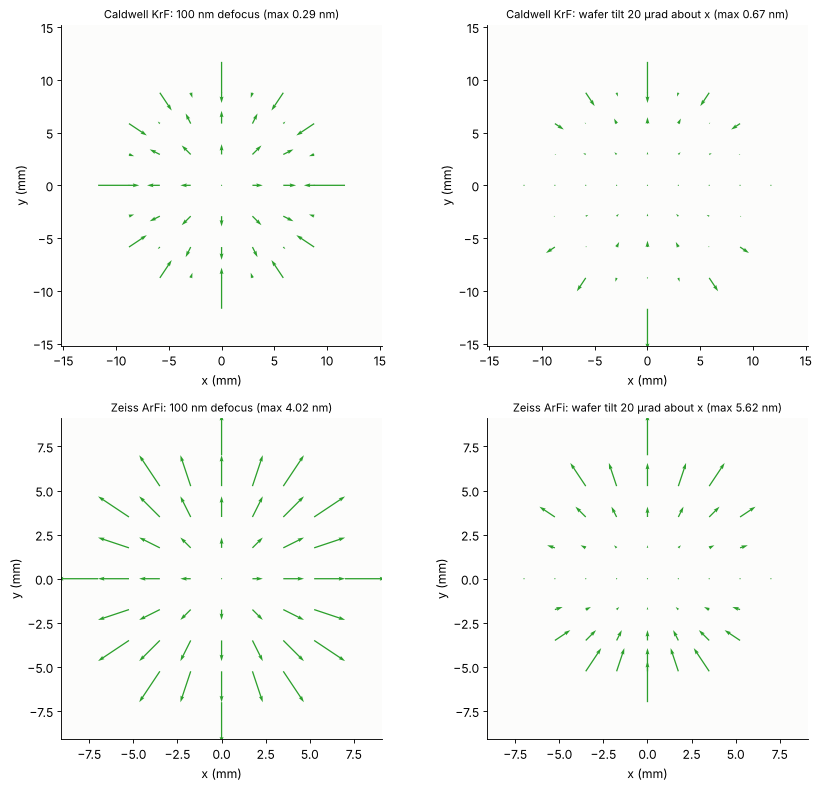

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row, (name, (field, H, focus, tilt, d_sh, kf, kt)) in zip(axes, cases.items()):
    for ax, dd, lab in [(row[0], focus, "100 nm defocus"), (row[1], tilt, "wafer tilt 20 µrad about x")]:
        mx = np.max(np.hypot(dd[:, 0], dd[:, 1]))
        ax.quiver(field[:, 0], field[:, 1], dd[:, 0], dd[:, 1], angles="xy", scale_units="xy",
                  scale=3*mx/H if mx > 0 else 1, width=0.004, color="C2")
        ax.set_title("{}: {} (max {:.2f} nm)".format(name, lab, mx), fontsize=10)
        ax.set_aspect("equal"), ax.set_xlabel("x (mm)"), ax.set_ylabel("y (mm)")
        ax.set_xlim(-1.3*H, 1.3*H), ax.set_ylim(-1.3*H, 1.3*H)
plt.tight_layout()

- **Zeiss ArFi**: 100 nm of defocus give 4.1 nm of magnification at the
  edge (0.59 ppm), a 20 µrad tilt 5.6 nm of keystone ($k_8 = k_9$), both
  exactly $z\,t$ (the traced image plane shift agrees to $10^{-3}$ nm). In a
  scanner this is why a lens that is not telecentric needs a very flat focus:
  the wafer height map becomes an overlay map.
- **Caldwell**: below 1 nm. Its telecentricity is not linear in the field
  ($+0.9$ mrad at mid field, $-2.9$ mrad at the edge), so defocus gives a
  little magnification plus third order distortion of opposite sign, and the
  wafer tilt a mix of second order terms instead of a clean keystone.
  (With the whole cone instead of the chief ray, the ten times larger
  telecentricity of a point source applies, see above.)

## Summary

| property | in the wavefront / pupil | field dependence | example here |
|---|---|---|---|
| translation | $Z_2$, $Z_3$ about the nominal point | constant | – |
| magnification | $Z_2 \propto x$, $Z_3 \propto y$ ($W_{111}$) | linear | element shifts, $Z_4$ sag near the field |
| radial distortion | $Z_2 \propto x r^2$, $Z_3 \propto y r^2$ ($W_{311}$), $r^4$ … | cubic, quintic | Caldwell design, $Z_9$ sag near the field |
| anamorphic, skew | $Z_2 \propto x$, $Z_3 \propto -y$; $Z_2 \propto y$, $Z_3 \propto x$ | linear, not rotational | $Z_5$, $Z_6$ sag near the field |
| keystone, bow, rotation | quadratic / linear with curl | not a gradient | tilted or rotated parts, wafer tilt × telecentricity |
| focus over the field | $Z_4(x, y)$ | any | field curvature, sag height near the field |
| telecentricity | centroid $\langle\mathbf P\rangle$ of the *intensity*: pupil decentre, intensity $Z_2$/$Z_3$ ($a_2/4a_1$); not the phase | $\mathbf t(x, y)$ | Zeiss chief rays, pupil coma of Caldwell |
| placement through focus | effective tilt $4\,c_4\langle\mathbf P\rangle$ | $z\,\mathbf t(x, y)$ | magnification and keystone from defocus and wafer tilt |

- "Distortion" depends on the observer: chief ray, Zernike tilt and centroid
  agree for a well corrected lens and differ by the tilt content of coma
  ($Z_7$, $Z_{14}$, … all move the centroid like $Z_2$) when it is not.
- A shape near the pupil is a wavefront aberration at all fields; the same
  shape near the field is a grid term (its gradient) and a focus map (its
  height). Only curl free grid terms can be made by plates.
- Telecentricity is not a wavefront property: the phase never makes the
  image drift through focus, the distribution of the light over the pupil
  does, and it depends on the illumination and the pattern.

In [24]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 54 s


## References

- H. H. Hopkins, *Wave Theory of Aberrations*, Clarendon Press (1950) (the wave aberration expansion in field and pupil, $W_{111}$ and $W_{311}$).
- J. Sasián, *Introduction to Aberrations in Optical Imaging Systems*, Cambridge University Press (2013) (field dependence of the wave aberration terms, distortion as a tilt).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986) (Seidel sums, $S_V$).
- K. P. Thompson, "Description of the third-order optical aberrations of near-circular pupil optical systems without symmetry", J. Opt. Soc. Am. A 22, 1389-1401 (2005).
- R. J. Noll, "Zernike polynomials and atmospheric turbulence", J. Opt. Soc. Am. 66, 207-211 (1976).
- J. W. Goodman, *Introduction to Fourier Optics*, 3rd ed., Roberts & Company (2005) (angular spectrum).
- H. J. Levinson, *Principles of Lithography*, 4th ed., SPIE Press (2019) (overlay, intrafield grid models, telecentricity).
- H. J. Levinson, *Lithography Process Control*, SPIE Press (1999) (overlay models).
- C. Mack, *Fundamental Principles of Optical Lithography: The Science of Microfabrication*, Wiley (2007).
- A. Erdmann, *Optical and EUV Lithography: A Modeling Perspective*, SPIE Press (2021).
- J. B. Caldwell, "All-fused-silica 248-nm lithographic projection lens", Optics & Photonics News 9(11), 40-41 (1998).
- H.-J. Rostalski, A. Dodoc, A. Epple and H. Beierl, "Refractive projection objective for immersion lithography", US 7,187,503 B2 (2007).